In [26]:
import mysql.connector
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 110

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [27]:
def get_connection():
    return mysql.connector.connect(
        host="localhost",
        user="root",
        password="",
        database="marketdata"
    )


db = get_connection()

df = pd.read_sql(
    """
    SELECT *
    FROM labeled_flatdata
    WHERE edited = 1
    """,
    db
)

db.close()

print("Dataset loaded:", df.shape)

C:\Users\nishw\AppData\Local\Temp\ipykernel_23432\3707626508.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(


Dataset loaded: (2225, 410)


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Columns: 407 entries, id to edittime
dtypes: datetime64[ns](1), float64(321), int64(2), object(83)
memory usage: 6.9+ MB


In [28]:
display(df.describe().T)

,count,mean,min,25%,50%,75%,max,std
id,2225.0,59326.511461,1.0,557.0,1113.0,224805.0,281219.0,99697.711936
anchor_price,2225.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
time_remaining_H4_minutes,2225.0,121.6,5.0,60.0,120.0,180.0,240.0,69.106268
time_remaining_H1_minutes,2225.0,32.395506,5.0,15.0,30.0,45.0,60.0,17.23113
time_remaining_M15_minutes,2225.0,9.986517,5.0,5.0,10.0,15.0,15.0,4.081543
...,...,...,...,...,...,...,...,...
M5_20_high,2225.0,0.154148,0.0,0.04,0.1,0.2,2.87,0.180891
M5_20_low,2225.0,-0.155056,-1.75,-0.21,-0.1,-0.04,0.0,0.180645
M5_20_close,2225.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
edited,2225.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0


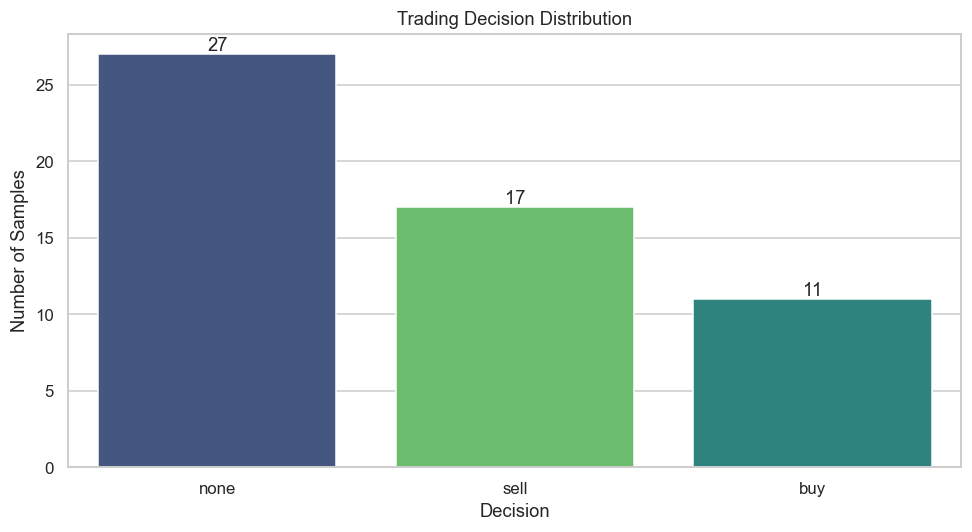

In [29]:
plt.figure(figsize=(9, 5))

order = df["decision"].value_counts().index

ax = sns.countplot(
    data=df,
    x="decision",
    order=order,
    hue="decision",
    palette="viridis",
    legend=False
)

plt.title("Trading Decision Distribution")
plt.xlabel("Decision")
plt.ylabel("Number of Samples")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

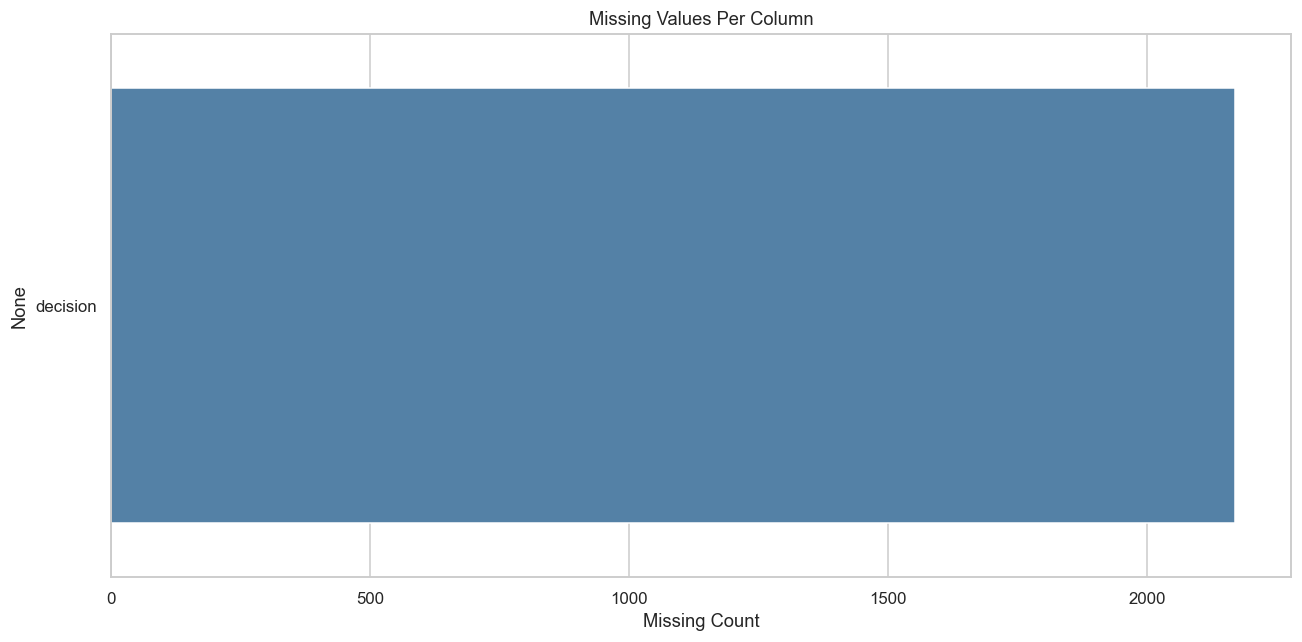

In [6]:
missing = df.isna().sum()

missing = missing[missing > 0].sort_values(
    ascending=False
)

plt.figure(figsize=(12, 6))

if len(missing):
    sns.barplot(
        x=missing.values,
        y=missing.index,
        color="steelblue"
    )
    plt.title("Missing Values Per Column")
    plt.xlabel("Missing Count")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found!")

In [7]:
for timeframe in ["H4", "H1", "M15", "M5"]:

    candle = f"{timeframe}_01"

    open_col = f"{candle}_open"
    high_col = f"{candle}_high"
    low_col = f"{candle}_low"
    close_col = f"{candle}_close"

    df[f"{timeframe}_body"] = (
        df[close_col] - df[open_col]
    )

    df[f"{timeframe}_range"] = (
        df[high_col] - df[low_col]
    )

    df[f"{timeframe}_upper_wick"] = (
        df[high_col] -
        df[[open_col, close_col]].max(axis=1)
    )

    df[f"{timeframe}_lower_wick"] = (
        df[[open_col, close_col]].min(axis=1) -
        df[low_col]
    )

print("Candle features generated!")

Candle features generated!


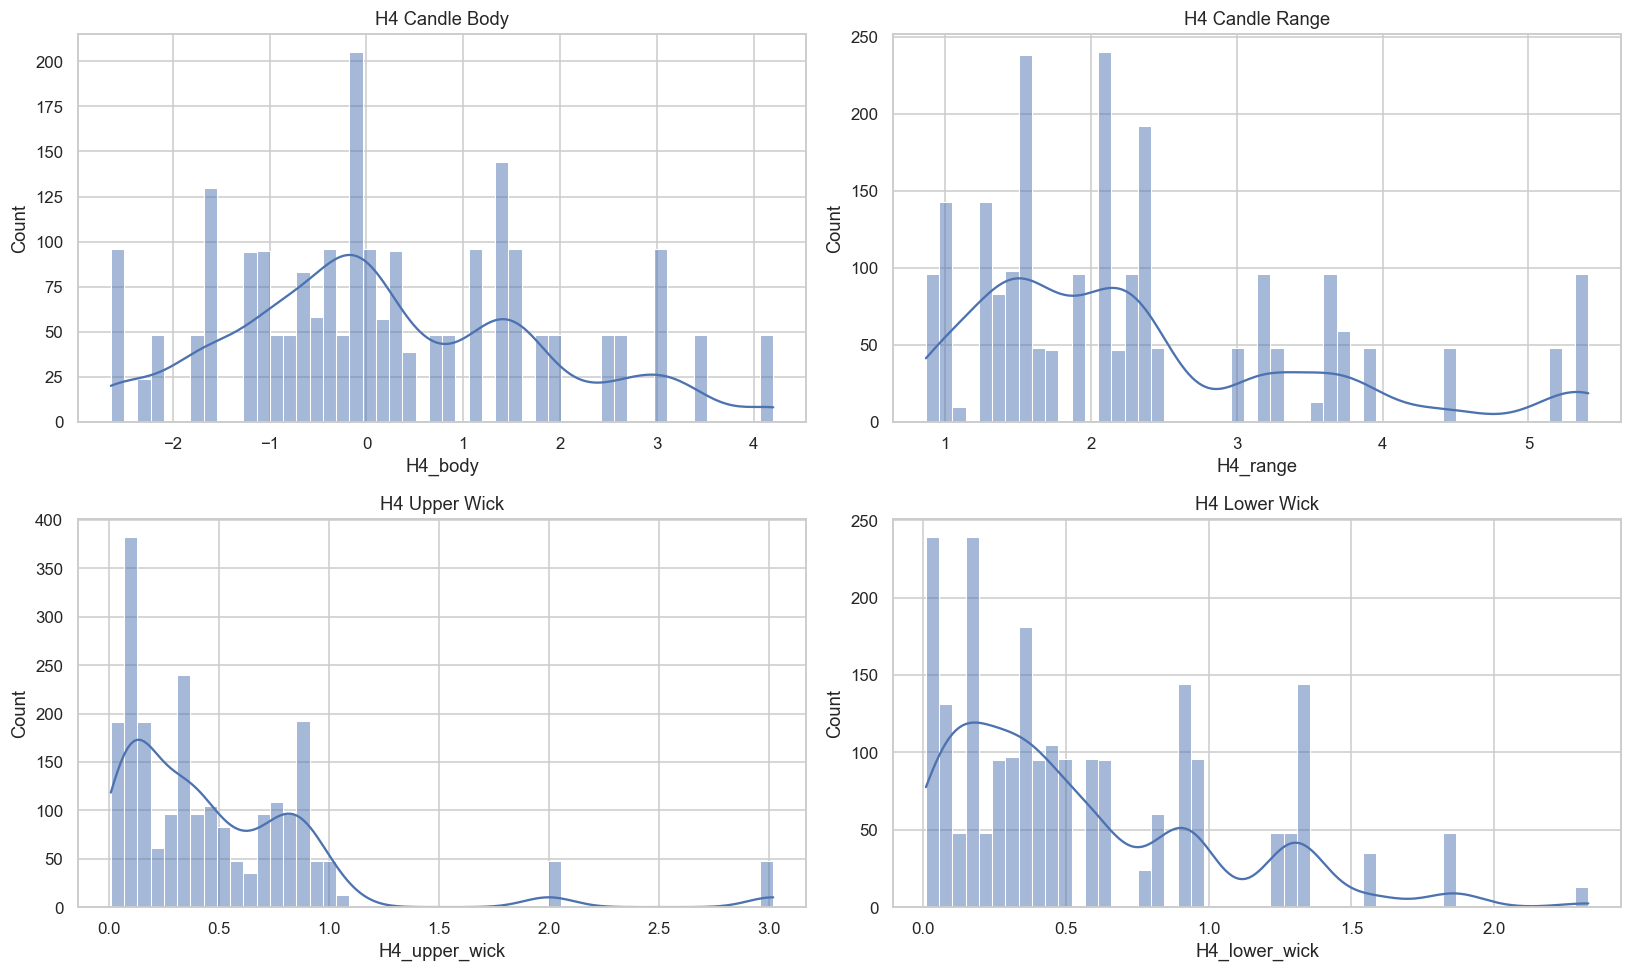

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

features = [
    ("H4_body", "H4 Candle Body"),
    ("H4_range", "H4 Candle Range"),
    ("H4_upper_wick", "H4 Upper Wick"),
    ("H4_lower_wick", "H4 Lower Wick")
]

for ax, (column, title) in zip(axes.flatten(), features):

    sns.histplot(
        df[column].dropna(),
        bins=50,
        kde=True,
        ax=ax
    )

    ax.set_title(title)

plt.tight_layout()
plt.show()

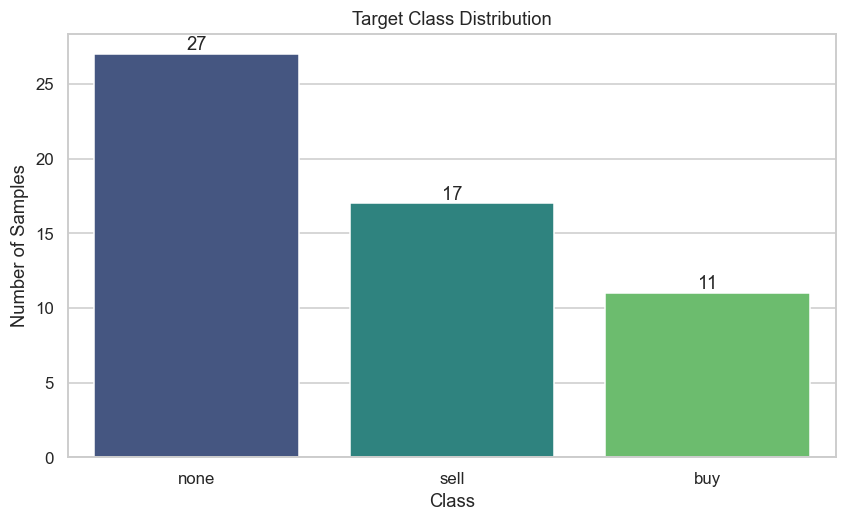

In [9]:
plt.figure(figsize=(9, 5))

counts = df["decision"].value_counts()

ax = sns.barplot(
    x=counts.index,
    y=counts.values,
    hue=counts.index,
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Target Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")

plt.show()

In [13]:
TIMEFRAMES = {
    "H4": 20,
    "H1": 20,
    "M15": 20,
    "M5": 20,
}

OHLC_COLUMNS = ["open", "high", "low", "close"]

# Generate feature names
feature_columns = [
    f"{tf}_{i:02d}_{col}"
    for tf, count in TIMEFRAMES.items()
    for i in range(1, count + 1)
    for col in OHLC_COLUMNS
]

# Create feature matrix
X = df[feature_columns].copy()

X = X.apply(pd.to_numeric, errors="coerce")

X = X.replace([np.inf, -np.inf], np.nan)

print("Features:", len(feature_columns))
print("Dataset shape:", X.shape)

Features: 320
Dataset shape: (2225, 320)


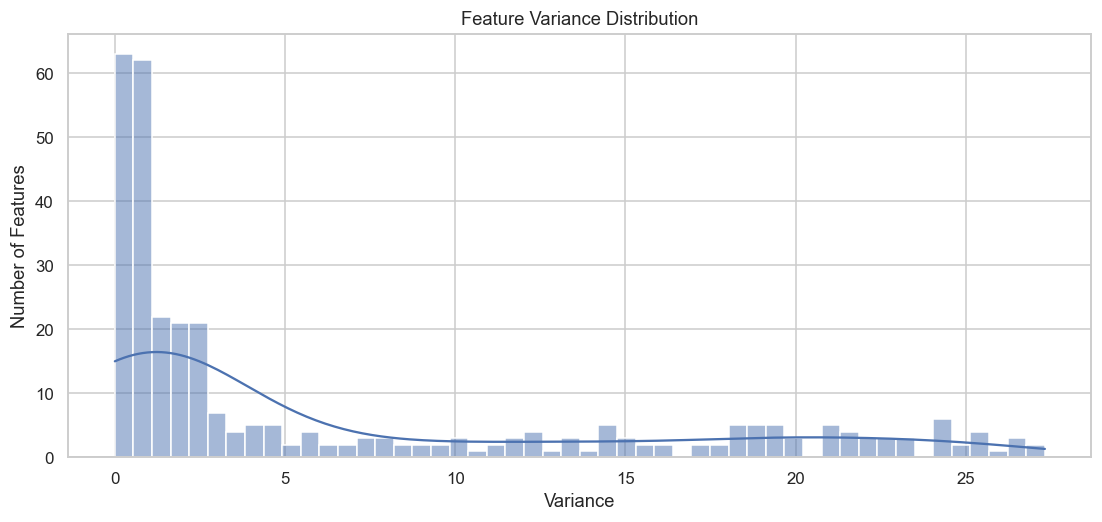

In [14]:
variance = X.var()

plt.figure(figsize=(12, 5))

sns.histplot(
    variance,
    bins=50,
    kde=True
)

plt.title("Feature Variance Distribution")
plt.xlabel("Variance")
plt.ylabel("Number of Features")

plt.show()

In [15]:
print("Average variance:", variance.mean())
print("Minimum variance:", variance.min())
print("Maximum variance:", variance.max())

print("Zero variance features:", (variance == 0).sum())

Average variance: 6.5191734329775795
Minimum variance: 0.0
Maximum variance: 27.319596490663645
Zero variance features: 4


In [16]:
constant_features = variance[
    variance == 0
]

print("Constant features:")

for feature in constant_features.index:
    print(
        feature,
        "| Value:",
        X[feature].iloc[0]
    )

Constant features:
H4_20_close | Value: 0.0
H1_20_close | Value: 0.0
M15_20_close | Value: 0.0
M5_20_close | Value: 0.0


In [17]:
constant_features = X.columns[
    X.nunique(dropna=False) <= 1
]

X = X.drop(
    columns=constant_features
)

print("Removed:", len(constant_features))
print("Remaining:", X.shape)

Removed: 4
Remaining: (2225, 316)


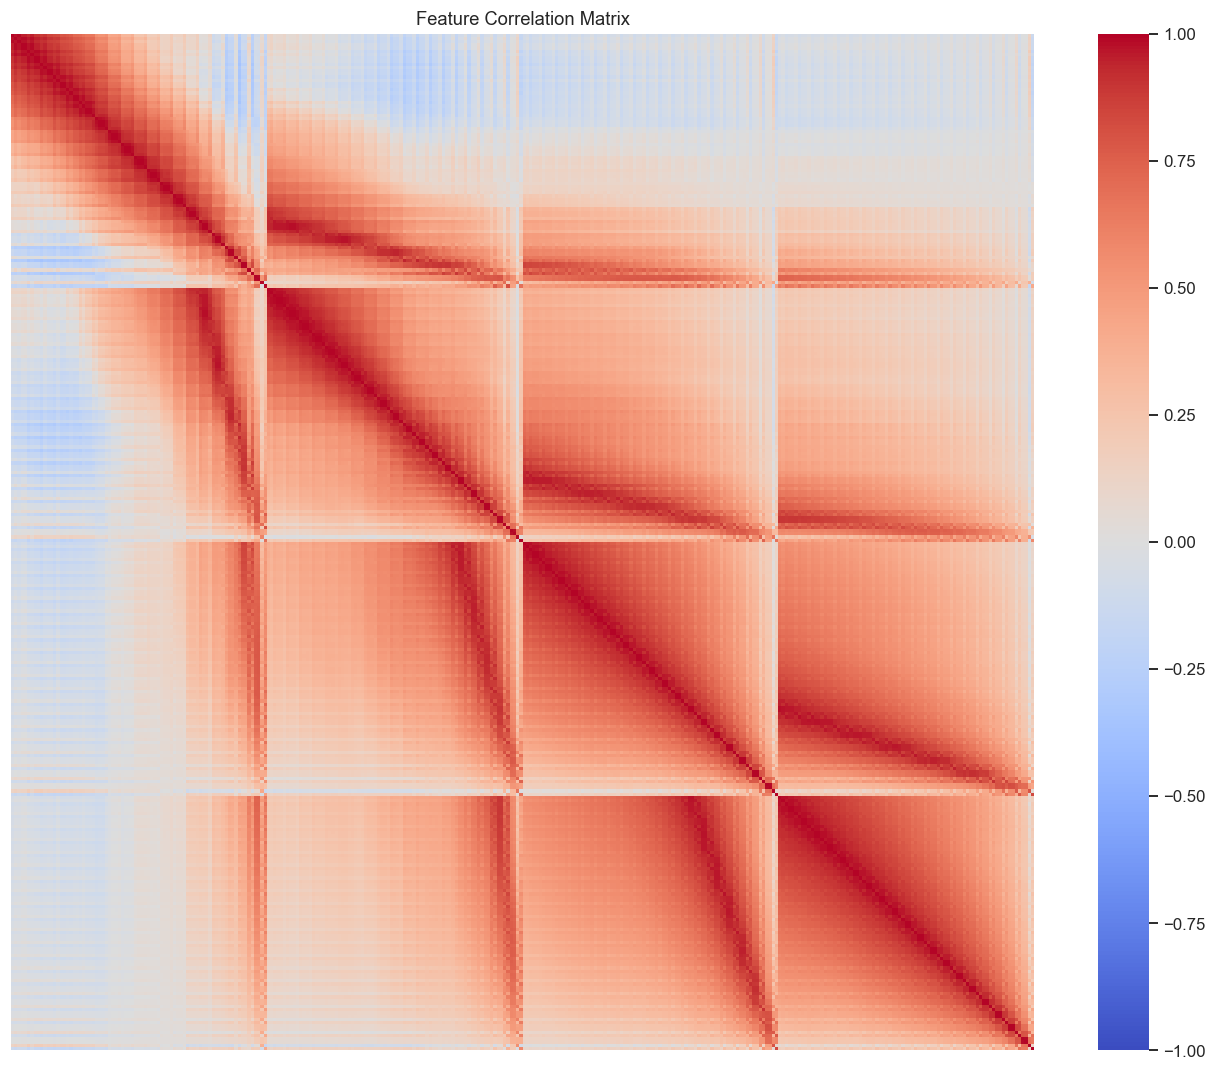

In [18]:
correlation = X.corr()

plt.figure(figsize=(15, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False
)

plt.title("Feature Correlation Matrix")

plt.show()

In [19]:
corr_pairs = (
    correlation
    .where(
        np.triu(
            np.ones(correlation.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

corr_pairs["Abs Correlation"] = (
    corr_pairs["Correlation"].abs()
)

high_corr = corr_pairs[
    corr_pairs["Abs Correlation"] >= 0.95
].sort_values(
    "Abs Correlation",
    ascending=False
)

display(high_corr.head(30))

,Feature 1,Feature 2,Correlation,Abs Correlation
22509,H1_01_close,H1_02_open,0.999549,0.999549
23435,H1_02_close,H1_03_open,0.999541,0.999541
24345,H1_03_close,H1_04_open,0.999504,0.999504
11544,H4_10_close,H4_11_open,0.999502,0.999502
10430,H4_09_close,H4_10_open,0.999484,0.999484
942,H4_01_close,H4_02_open,0.999481,0.999481
12642,H4_11_close,H4_12_open,0.999475,0.999475
25239,H1_04_close,H1_05_open,0.999457,0.999457
13724,H4_12_close,H4_13_open,0.999457,0.999457
9300,H4_08_close,H4_09_open,0.999445,0.999445


In [20]:
thresholds = [0.90, 0.95, 0.99, 0.999]

for threshold in thresholds:

    count = (
        corr_pairs["Abs Correlation"] >= threshold
    ).sum()

    print(
        f"Correlation >= {threshold}: {count} pairs"
    )

Correlation >= 0.9: 2123 pairs
Correlation >= 0.95: 782 pairs
Correlation >= 0.99: 72 pairs
Correlation >= 0.999: 37 pairs


In [21]:
def select_uncorrelated_features(X, threshold=0.95):

    corr = X.corr().abs()

    upper = corr.where(
        np.triu(
            np.ones(corr.shape),
            k=1
        ).astype(bool)
    )

    to_drop = [
        column
        for column in upper.columns
        if (upper[column] >= threshold).any()
    ]

    selected = X.drop(columns=to_drop)

    return selected, to_drop


X_reduced, removed_features = select_uncorrelated_features(
    X,
    threshold=0.95
)

print("Original features:", X.shape[1])
print("Removed features:", len(removed_features))
print("Remaining features:", X_reduced.shape[1])

Original features: 316
Removed features: 226
Remaining features: 90


In [22]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder

# Original 320 features, including the four constant features
X_baseline = df[feature_columns].copy()

X_baseline = X_baseline.apply(
    pd.to_numeric,
    errors="coerce"
).replace([np.inf, -np.inf], np.nan)

y_raw = df["decision"].fillna("").astype(str).str.strip()

valid = y_raw.ne("") & ~y_raw.str.lower().isin(["nan", "null"])

X_baseline = X_baseline.loc[valid]
y_raw = y_raw.loc[valid]

encoder = LabelEncoder()
y = encoder.fit_transform(y_raw)

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

predictions = cross_val_predict(
    model,
    X_baseline,
    y,
    cv=cv,
    n_jobs=1
)

print("Accuracy:", accuracy_score(y, predictions))

print("\nClassification Report:")

print(classification_report(
    y,
    predictions,
    target_names=encoder.classes_
))

Accuracy: 0.6545454545454545

Classification Report:
              precision    recall  f1-score   support

         buy       0.25      0.09      0.13        11
        none       0.66      0.78      0.71        27
        sell       0.74      0.82      0.78        17

    accuracy                           0.65        55
   macro avg       0.55      0.56      0.54        55
weighted avg       0.60      0.65      0.62        55



In [23]:
distribution = (
    df["decision"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(
    pd.DataFrame({
        "Count": df["decision"].value_counts(),
        "Percentage": distribution
    })
)

,Count,Percentage
decision,,
none,27,49.09
sell,17,30.91
buy,11,20.00


In [24]:
db = get_connection()

distribution = pd.read_sql("""
    SELECT
        decision,
        COUNT(*) AS total
    FROM labeled_flatdata
    WHERE edited = 1
    GROUP BY decision
    ORDER BY total DESC
""", db)

db.close()

display(distribution)

C:\Users\nishw\AppData\Local\Temp\ipykernel_23432\194406891.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  distribution = pd.read_sql("""


,decision,total
0,None,2170
1,none,27
2,sell,17
3,buy,11


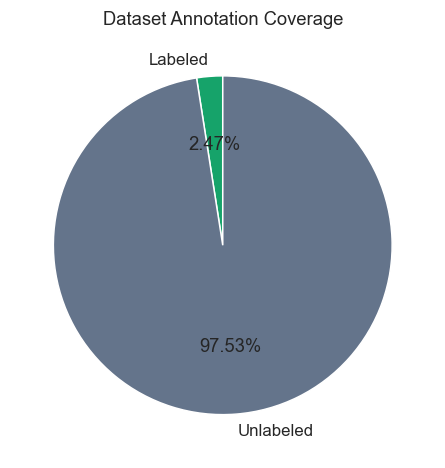

In [25]:
total = 2225

labeled = 55
unlabeled = total - labeled

plt.figure(figsize=(8, 5))

plt.pie(
    [labeled, unlabeled],
    labels=["Labeled", "Unlabeled"],
    autopct="%1.2f%%",
    colors=["#16a36a", "#64748b"],
    startangle=90
)

plt.title("Dataset Annotation Coverage")

plt.show()